In [20]:
import cudf
import cuml
import cupy as cp
import matplotlib.pyplot as plt
import seaborn as sns
from cuml.model_selection import train_test_split
from cuml.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from cuml.decomposition import PCA
from cuml.cluster.hdbscan import HDBSCAN
import numpy as np
import warnings
import kagglehub
from sklearn.metrics import confusion_matrix
warnings.filterwarnings('ignore')

In [2]:
cuml.set_global_output_type('cupy')

In [3]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [4]:
def print_confusion_matrix(cm, title):
    print(f"{title}:")
    print("         Predicted")
    print("         Not Fraud  Fraud")
    print("Actual")
    print(f"Not Fraud  {cm[0,0]:6d}  {cm[0,1]:6d}")
    print(f"Fraud      {cm[1,0]:6d}  {cm[1,1]:6d}")

In [5]:
path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/banksim1


In [6]:
data = cudf.read_csv(path + '/bs140513_032310.csv')

In [7]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype('float32')

In [8]:
data['amount'] = data['amount'].astype('float32')
data['amount_thresh'] = cudf.Series('>3000', index=data.index)
data.loc[data['amount'] <= 500, 'amount_thresh'] = '0-500'
data.loc[(data['amount'] > 500) & (data['amount'] <= 1000), 'amount_thresh'] = '500-1000'
data.loc[(data['amount'] > 1000) & (data['amount'] <= 1500), 'amount_thresh'] = '1000-1500'
data.loc[(data['amount'] > 1500) & (data['amount'] <= 2000), 'amount_thresh'] = '1500-2000'
data.loc[(data['amount'] > 2000) & (data['amount'] <= 2500), 'amount_thresh'] = '2000-2500'
data.loc[(data['amount'] > 2500) & (data['amount'] <= 3000), 'amount_thresh'] = '2500-3000'

In [9]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = cp.arange(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = cp.arange(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = cp.arange(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = cp.arange(1, len(amount_thresh) + 1)

In [10]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [11]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [12]:
ohe = OneHotEncoder(sparse=True, handle_unknown='ignore')
ohe_cols = ['age', 'gender', 'category', 'amount_thresh']
ohe_data = ohe.fit_transform(data[ohe_cols])
ohe_feature_names = ohe.get_feature_names(ohe_cols)
# Convert sparse matrix to dense CuPy array before creating DataFrame
ohe_data = cudf.DataFrame(ohe_data.toarray(), columns=ohe_feature_names)
data = cudf.concat([data.drop(ohe_cols, axis=1), ohe_data], axis=1)

In [13]:
le = LabelEncoder()
data['fraud'] = le.fit_transform(data['fraud'])

print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [14]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
scaled_data_big = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data_big)
pca_df = cudf.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

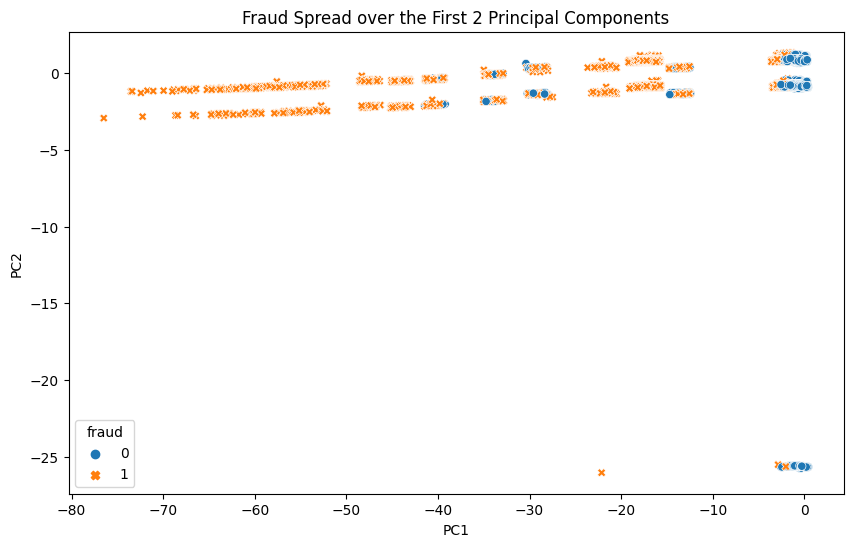

Explained variance ratio: [0.09856005 0.06097403]


In [15]:
pca_df_np = pca_df.to_pandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df_np)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

print("Explained variance ratio:", cp.asnumpy(pca.explained_variance_ratio_))

In [16]:
X = data.drop('fraud', axis=1)
y = data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

In [17]:
X_sample = X_train.copy()
y_sample = y_train.copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)



Confusion Matrix: HDBSCAN Clusters vs. Fraud Labels:
         Predicted
         Not Fraud  Fraud
Actual
Not Fraud       0       0
Fraud       57743      13


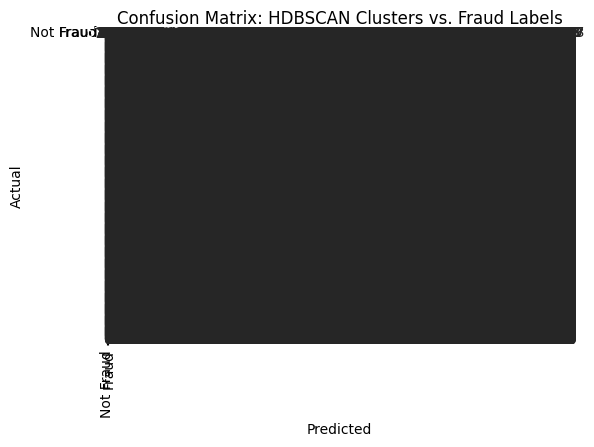

Cluster Persistence Scores: [[0.00099131 0.0085434  0.0039462  0.00840164 0.00909363 0.00675569
  0.00655291 0.00698961 0.00913447 0.00723837 0.04194104 0.00474711
  0.03306707 0.02403125 0.00447916 0.00585108 0.02640797 0.02065732
  0.02123116 0.04586593 0.03122473 0.03986239 0.029721   0.03246503
  0.04588668 0.03253158 0.02050719 0.00467831 0.00410446 0.05986389
  0.02138639 0.03475999 0.01087343 0.01814166 0.05068651 0.03204385
  0.04543907 0.04644005 0.03008443 0.02089355 0.04968351 0.02053909
  0.02592622 0.02155632 0.02706731 0.03235173 0.09403528 0.01923257
  0.02783551 0.02080263 0.01099903 0.03961895 0.05345235 0.08330113
  0.02725613 0.02795567 0.0153464  0.09569427 0.06446153 0.05857643
  0.02671139 0.02839703 0.05512709 0.036894   0.03173761 0.00673122
  0.04665878 0.05045375 0.12762466 0.05286132 0.03689172 0.01895845
  0.05894511 0.09563368 0.12114486 0.0462387  0.09329029 0.11199711
  0.14403641 0.13202952 0.10513    0.00871528 0.05610254 0.01166587
  0.08571748 0.00672

In [21]:
hdbscan_model = HDBSCAN(
    min_cluster_size=100, 
    min_samples=50,       
    cluster_selection_method='eom', 
    metric='euclidean',    
    prediction_data=True,  
    verbose=False
)

hdbscan_model.fit(X_scaled)

cluster_labels = hdbscan_model.labels_
probabilities = hdbscan_model.probabilities_

cluster_labels_np = cp.asnumpy(cluster_labels)
y_sample_np = cp.asnumpy(y_sample)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=cp.asnumpy(X_scaled[:, 0]),  # Assuming first feature for x-axis
    y=cp.asnumpy(X_scaled[:, 1]),  # Assuming second feature for y-axis
    hue=cluster_labels_np,         # Cluster labels
    style=y_sample_np,             # Fraud labels
    palette='deep'
)
plt.title('HDBSCAN Clusters vs. Fraud Labels')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend(title='Cluster & Fraud')
plt.show()

cm = confusion_matrix(y_sample_np, cluster_labels_np)
print_confusion_matrix(cm, title="Confusion Matrix: HDBSCAN Clusters vs. Fraud Labels")
draw_confusion_matrix(cm, title="Confusion Matrix: HDBSCAN Clusters vs. Fraud Labels")

print("Cluster Persistence Scores:", cp.asnumpy(hdbscan_model.cluster_persistence_))